# **4. HUẤN LUYỆN CÁC MÔ HÌNH HỌC MÁY**

Khởi tạo dữ liệu ban đầu.

In [70]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

FIG_DIR = Path('figures')  # [UPDATED] Thư mục lưu hình để chèn vào báo cáo
FIG_DIR.mkdir(exist_ok=True)

PROCESSED_DIR = Path('data/processed')
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
NO_COMPETITOR_DISTANCE = 999999

def save_fig(name):
    """[UPDATED] Lưu hình đang vẽ vào figures/<name>.png."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150)

with open(PROCESSED_DIR / 'config.json', encoding='utf-8') as f:
    cfg = {k: pd.Timestamp(v) for k, v in json.load(f).items()}

# [UPDATED] Đọc dữ liệu sạch do notebook 01 lưu, nên notebook này chạy độc lập được
my_data = pd.read_csv('data/processed/rossmann_add_features.csv', parse_dates=['Date'], dtype={'StateHoliday': str})
my_data['Date'] = pd.to_datetime(my_data['Date'])
data_root = pd.read_csv('data/processed/rossmann_clean.csv', parse_dates=['Date'], dtype={'StateHoliday': str})
data_root['Date'] = pd.to_datetime(data_root['Date'])
X_fourier = pd.read_csv('data/processed/X_fourier.csv')
X_fourier['Date'] = pd.to_datetime(X_fourier['Date'])
X_fourier = X_fourier.set_index('Date')
TRAIN_END      = cfg['TRAIN_END']
VALID_END      = cfg['VALID_END']
print(my_data.shape)

(844338, 35)


**4.1 Chuẩn bị dữ liệu cho mô hình học máy**

Tạo dữ liệu cho mô hình học và dự đoán.

In [71]:
col_str = ['StoreType' , 'Assortment']
my_data[col_str] = my_data[col_str].astype('category')
X_train = my_data[my_data['Date'] <= TRAIN_END]
X_valid = my_data[(my_data['Date'] > TRAIN_END) & (my_data['Date'] <= VALID_END)]
X_test = my_data[my_data['Date'] > VALID_END]
y_train = X_train['Sales']
y_train_log = np.log1p(y_train)
y_valid = X_valid['Sales']
y_valid_log = np.log1p(y_valid)
y_test = X_test['Sales']
y_test_log = np.log1p(y_test)
X_train = X_train.drop(columns=['Sales' , 'Date'])
X_valid = X_valid.drop(columns=['Sales' , 'Date'])
X_test = X_test.drop(columns=['Sales' , 'Date'])

Tạo một số hàm hỗ trợ cho mô hình học máy.

In [104]:
def get_importance(model):
    name = type(model).__name__
    if name.startswith('LGBM'):
        b = model.booster_
        imp = pd.Series(b.feature_importance(importance_type='gain'), index=b.feature_name())
    elif name.startswith('XGB'):
        score = model.get_booster().get_score(importance_type='total_gain')   # tổng gain, giống LightGBM
        imp = pd.Series(score).reindex(model.get_booster().feature_names, fill_value=0)
    else:                                   # Random Forest và các mô hình sklearn khác
        imp = pd.Series(model.feature_importances_, index=model.feature_names_in_)
    return (100 * imp / imp.sum()).sort_values(ascending=False)

def plot_importance_grouped(imp, model_name, top_n=10):
    feat2group = {f: g for g, fs in groups.items() for f in fs}
    palette = dict(zip(groups, sns.color_palette('Set2', len(groups))))
    palette['Khác'] = '#bbbbbb'

    top = imp.head(top_n).copy()
    top[f'Khác ({len(imp) - top_n} cột)'] = imp.iloc[top_n:].sum()
    colors = [palette.get(feat2group.get(f, 'Khác'), '#bbbbbb') for f in top.index]
    by_group = imp.groupby(imp.index.map(lambda f: feat2group.get(f, 'Khác'))).sum().sort_values()

    fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [1.4, 1]})
    for ax, data, cols, title in [
        (axes[0], top[::-1], colors[::-1], f'Top {top_n} đặc trưng quan trọng nhất'),
        (axes[1], by_group, [palette.get(g, '#bbbbbb') for g in by_group.index], 'Đóng góp theo nhóm đặc trưng'),
    ]:
        ax.barh(data.index, data.values, color=cols)
        for i, v in enumerate(data.values):
            ax.text(v + 0.5, i, f'{v:.1f}%', va='center', fontsize=9)
        ax.set_xlim(0, data.max() * 1.2)
        ax.set_title(title); ax.set_xlabel('Tỷ lệ đóng góp (%)')
    handles = [plt.Rectangle((0, 0), 1, 1, color=palette[g]) for g in groups]
    axes[0].legend(handles, groups.keys(), loc='lower right', fontsize=8)
    fig.suptitle(f'Mức đóng góp của đặc trưng: {model_name}')
    plt.tight_layout()
    save_fig(f'importance_{model_name.lower().replace(" ", "_")}')

def plot_learning_curve(model, model_name):
    name = type(model).__name__
    if name.startswith('LGBM'):
        ev, best = model.evals_result_, model.best_iteration_
        curves = {k: np.sqrt(v['l2']) for k, v in ev.items()}       # l2 → RMSE cho cùng thang với XGBoost
    else:
        ev, best = model.evals_result(), model.best_iteration
        curves = {('train' if k == 'validation_0' else 'valid'): v['rmse'] for k, v in ev.items()}

    plt.figure(figsize=(7, 4))
    for k, v in curves.items():
        plt.plot(v, label=k.capitalize())
    plt.axvline(best, ls='--', color='gray', label=f'Dừng sớm ({best} cây)')
    plt.xlabel('Số cây'); plt.ylabel('RMSE (thang log)')
    plt.title(f'Quá trình học của {model_name}')
    plt.legend(); plt.grid(alpha=0.3)
    save_fig(f'learning_curve_{model_name.lower()}')

def build_plot_df(model, sets):
    out = []
    for name, (X, y_log) in sets.items():
        out.append(pd.DataFrame({
            'Date':    my_data.loc[X.index, 'Date'].values,
            'Store':   my_data.loc[X.index, 'Store'].values,
            'Thực tế': np.expm1(np.asarray(y_log)),
            'Dự đoán': np.clip(np.expm1(model.predict(X)), 0, None),
            'Tập':     name,
        }))
    return pd.concat(out)

def plot_store(plot_df, store_id, model_name):
    colors = {'huấn luyện': 'red', 'kiểm định': 'blue', 'thi thử': 'green'}
    tap_list = [t for t in colors if t in plot_df['Tập'].unique()]
    fig, axes = plt.subplots(len(tap_list), 1, figsize=(15, 3.7 * len(tap_list)), squeeze=False)
    for ax, t in zip(axes[:, 0], tap_list):
        d = plot_df[(plot_df['Store'] == store_id) & (plot_df['Tập'] == t)].sort_values('Date')
        d = d.tail(100) if t == 'huấn luyện' else d
        ax.plot(d['Date'], d['Thực tế'], color='gray', alpha=0.7, label='Thực tế')
        ax.plot(d['Date'], d['Dự đoán'], color=colors[t], lw=2, label='Dự đoán')
        ax.set_title(f'{model_name}, cửa hàng {store_id}: tập {t}')
        ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout()
    save_fig(f'{model_name.lower()}_store_{store_id}')

sets = {'huấn luyện': (X_train, y_train_log),
        'kiểm định':  (X_valid, y_valid_log),
        'thi thử':    (X_test,  y_test_log)}        # bỏ dòng test nếu chưa tạo


**4.2 Huấn luyện mô hình hybrid**

Đưa dữ liệu về dạng thích hợp để mô hình học.

In [72]:
features_lgb = ['Store','StoreType','Assortment','CompetitionDistance','Promo2','Promo2SinceWeek',
    'DayOfWeek','Promo','Day','Month','CompetitorLongevity',
    'DaysSinceHoliday','DaystoHoliday','PromoPrev','PromoNext','PromoRun','LastPromo', 'Promo2_Active' ,
    'lag_49_resid' , 'lag_56_resid' , 'lag_63_resid' ]
time_cols = [c for c in X_fourier.columns if c not in ('const', 'Date')]
lag_cols  = ['lag_49', 'lag_56', 'lag_63']

# Bảng cột thời gian tra theo ngày
fourier_by_date = X_fourier.set_index('Date')[time_cols] if 'Date' in X_fourier.columns \
                  else X_fourier[time_cols]

tr = X_train.dropna(subset=lag_cols)
va = X_valid.dropna(subset=lag_cols)

def make_X(df):
    dates = my_data.loc[df.index, 'Date']             # ngày của từng dòng (X_train đã bỏ cột Date)
    X1 = fourier_by_date.reindex(dates.values)        # mỗi dòng cửa hàng–ngày nhận đúng cột thời gian của ngày đó
    X1.index = df.index                               # gắn lại index để khớp với df
    X1[lag_cols] = np.log1p(df[lag_cols])
    X2 = df[features_lgb].copy()
    return X1, X2

X_train_linear, X_train_lgb = make_X(tr)
X_valid_linear, X_valid_lgb = make_X(va)

# y lấy đúng các dòng còn lại sau dropna
y_train_hd = y_train_log.loc[tr.index]
y_valid_hd = y_valid_log.loc[va.index]

# Kiểm tra
print(len(X_train_linear), len(X_train_lgb), len(y_train_hd))     # 3 số bằng nhau
print(len(X_valid_linear), len(X_valid_lgb), len(y_valid_hd))
print(X_train_linear.isna().sum().sum(), X_valid_linear.isna().sum().sum())   # 0 0
print(X_train_linear['trend'].agg(['min', 'max']), X_valid_linear['trend'].agg(['min', 'max']))

683997 683997 683997
43098 43098 43098
0 0
min     64.0
max    844.0
Name: trend, dtype: float64 min    845.0
max    893.0
Name: trend, dtype: float64


Tạo mô hình hybrid.

In [73]:
from sklearn.base import BaseEstimator

class BoostedHybrid(BaseEstimator):
    def __init__(self, model_1, model_2):
        self.model_1 = model_1
        self.model_2 = model_2

    def fit(self, X_1, X_2, y, X_1_valid=None, X_2_valid=None, y_valid=None, patience=50):
        # Bước 1: tuyến tính học xu hướng + mùa vụ (chỉ trên train)
        self.model_1.fit(X_1, y)
        resid = y - self.model_1.predict(X_1)

        # Bước 2: LightGBM học phần dư, có dừng sớm
        fit_kw = {}
        if X_1_valid is not None:
            resid_valid = y_valid - self.model_1.predict(X_1_valid)
            fit_kw = dict(eval_set=[(X_2_valid, resid_valid)],
                          callbacks=[lgb.early_stopping(patience, verbose=False),
                                     lgb.log_evaluation(200)])
        self.model_2.fit(X_2, resid, **fit_kw)
        return self

    def predict(self, X_1, X_2):
        return self.model_1.predict(X_1) + self.model_2.predict(X_2)

In [74]:
from sklearn.linear_model import LinearRegression
import lightgbm as lgb
import warnings
warnings.filterwarnings('ignore', module='lightgbm')
model_hybrid = BoostedHybrid( model_1 = LinearRegression() , model_2 = lgb.LGBMRegressor(n_estimators = 3000 , learning_rate = 0.05 , max_depth = 10 , n_jobs = -1 , num_leaves = 127))
model_hybrid.fit(X_1=X_train_linear , X_2 = X_train_lgb , y=y_train_hd , X_1_valid=X_valid_linear , X_2_valid=X_valid_lgb , y_valid= y_valid_hd )
display(model_hybrid)

[200]	valid_0's l2: 0.0275114
[400]	valid_0's l2: 0.0254021
[600]	valid_0's l2: 0.0242594
[800]	valid_0's l2: 0.0235296
[1000]	valid_0's l2: 0.0231256
[1200]	valid_0's l2: 0.0228951
[1400]	valid_0's l2: 0.0227427
[1600]	valid_0's l2: 0.0225872
[1800]	valid_0's l2: 0.0225078
[2000]	valid_0's l2: 0.0224495
[2200]	valid_0's l2: 0.0223726


,model_1,LinearRegression()
,model_2,LGBMRegressor...um_leaves=127)
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
,num_leaves,127
,max_depth,10
,learning_rate,0.05
,n_estimators,3000


In [75]:
def decompose(X1, X2, y_log, idx):
    lin = model_hybrid.model_1.predict(X1)
    hyb = model_hybrid.predict(X1, X2)
    return (pd.DataFrame({'Date': my_data.loc[idx, 'Date'].values,
                          'Thực tế':                       np.expm1(np.asarray(y_log)),
                          'Bước 1: tuyến tính (xu hướng + mùa vụ)': np.expm1(lin),
                          'Bước 2: lai (+ LightGBM)':      np.expm1(hyb)})
              .groupby('Date').mean())

d_va = decompose(X_valid_linear, X_valid_lgb, y_valid_hd, va.index)

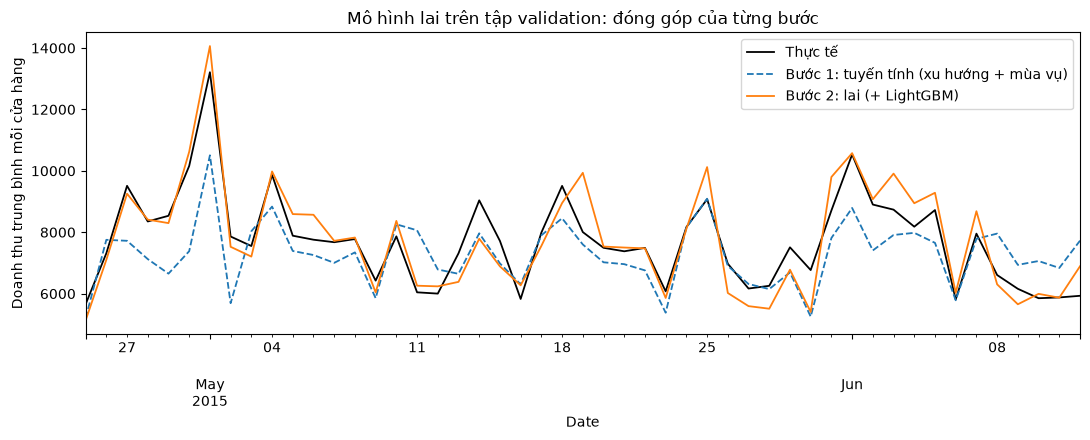

In [76]:
ax = d_va.plot(figsize=(11, 4.5), lw=1.3,
               style={'Thực tế': 'k-', 'Bước 1: tuyến tính (xu hướng + mùa vụ)': 'C0--',
                      'Bước 2: lai (+ LightGBM)': 'C1-'})
ax.set_ylabel('Doanh thu trung bình mỗi cửa hàng')
ax.set_title('Mô hình lai trên tập validation: đóng góp của từng bước')
save_fig('hybrid_decomposition')

**4.3 Huấn luyện mô hình LightGBM**

Tạo mô hình và bắt đầu huấn luyện mô hình.

In [ ]:
import lightgbm as lgb
import time
t0 = time.time()
model_lgb = lgb.LGBMRegressor(n_estimators=3000, learning_rate=0.1, num_leaves=127,
                      subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                      importance_type='gain', random_state=0, n_jobs=-1, verbose=-1)
model_lgb.fit(X_train, y_train_log, eval_set=[(X_valid, y_valid_log)],
          callbacks=[lgb.early_stopping(50), lgb.log_evaluation(200)])
print(f'số cây tối ưu: {model_lgb.best_iteration_}| {time.time() - t0:.0f} giây')

Training until validation scores don't improve for 50 rounds
[200]	valid_0's l2: 0.0130882
[400]	valid_0's l2: 0.0124036
[600]	valid_0's l2: 0.0121675
[800]	valid_0's l2: 0.0120152
[1000]	valid_0's l2: 0.0118628
[1200]	valid_0's l2: 0.0118015
[1400]	valid_0's l2: 0.0117365
Early stopping, best iteration is:
[1507]	valid_0's l2: 0.0116986
số cây tối ưu: 1507


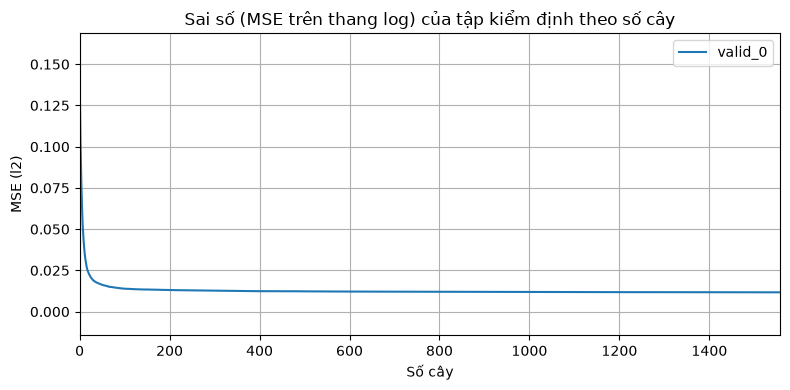

In [ ]:
plot_learning_curve(model_lgb , 'LightGBM')

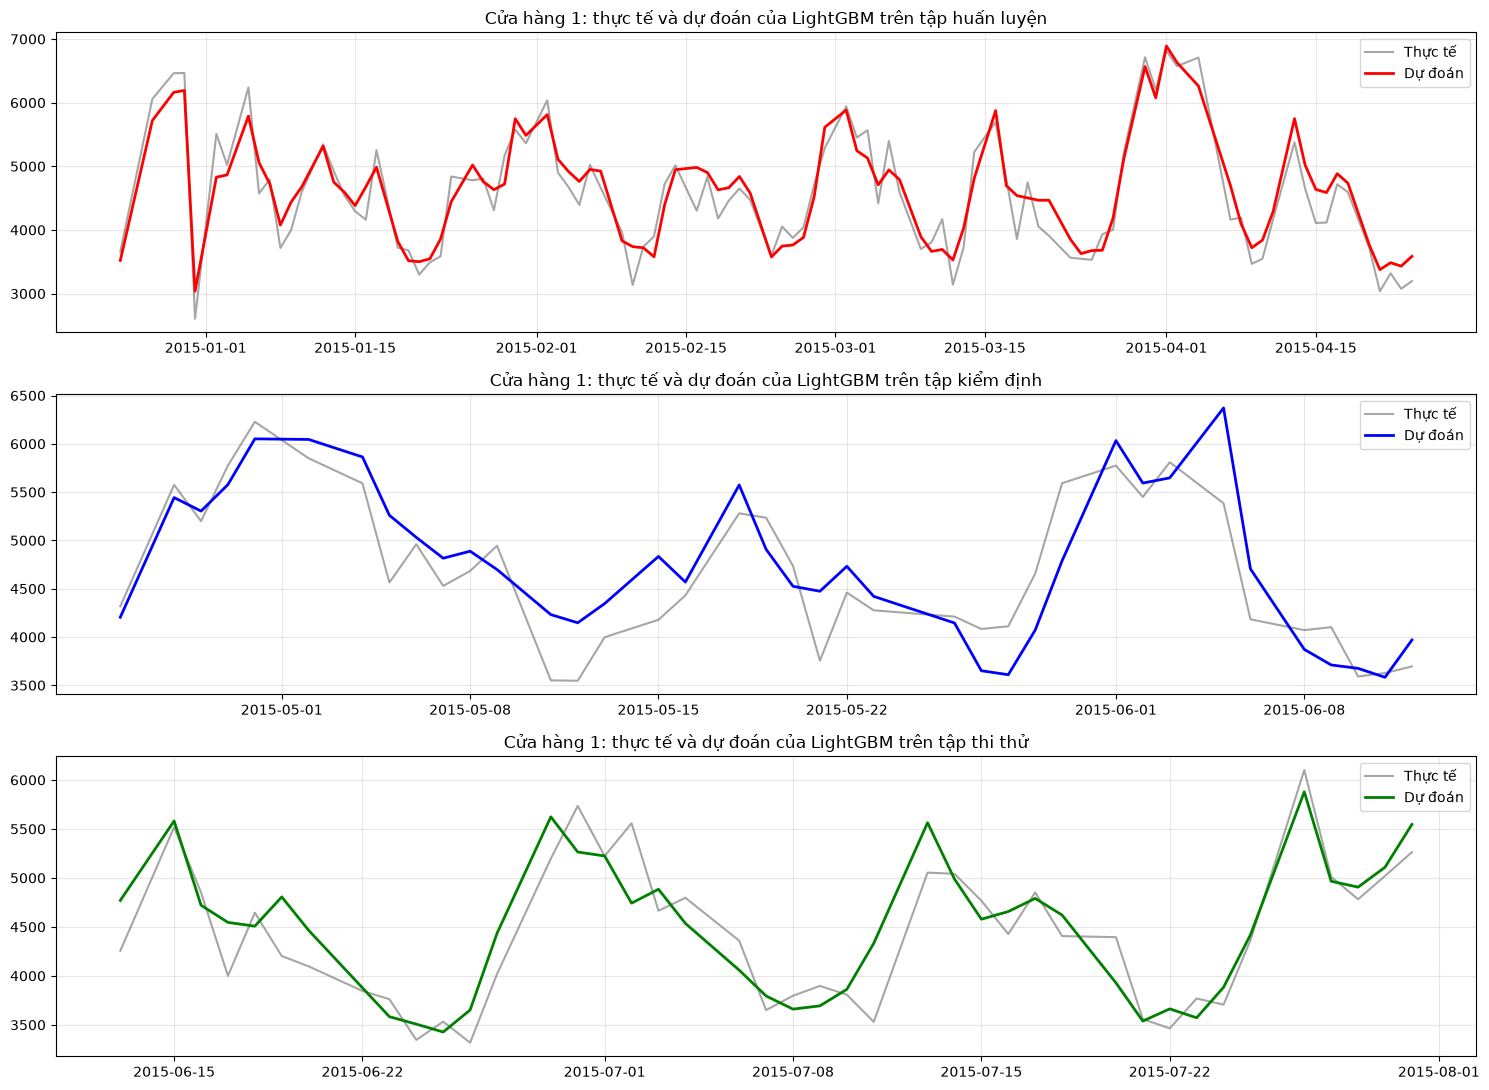

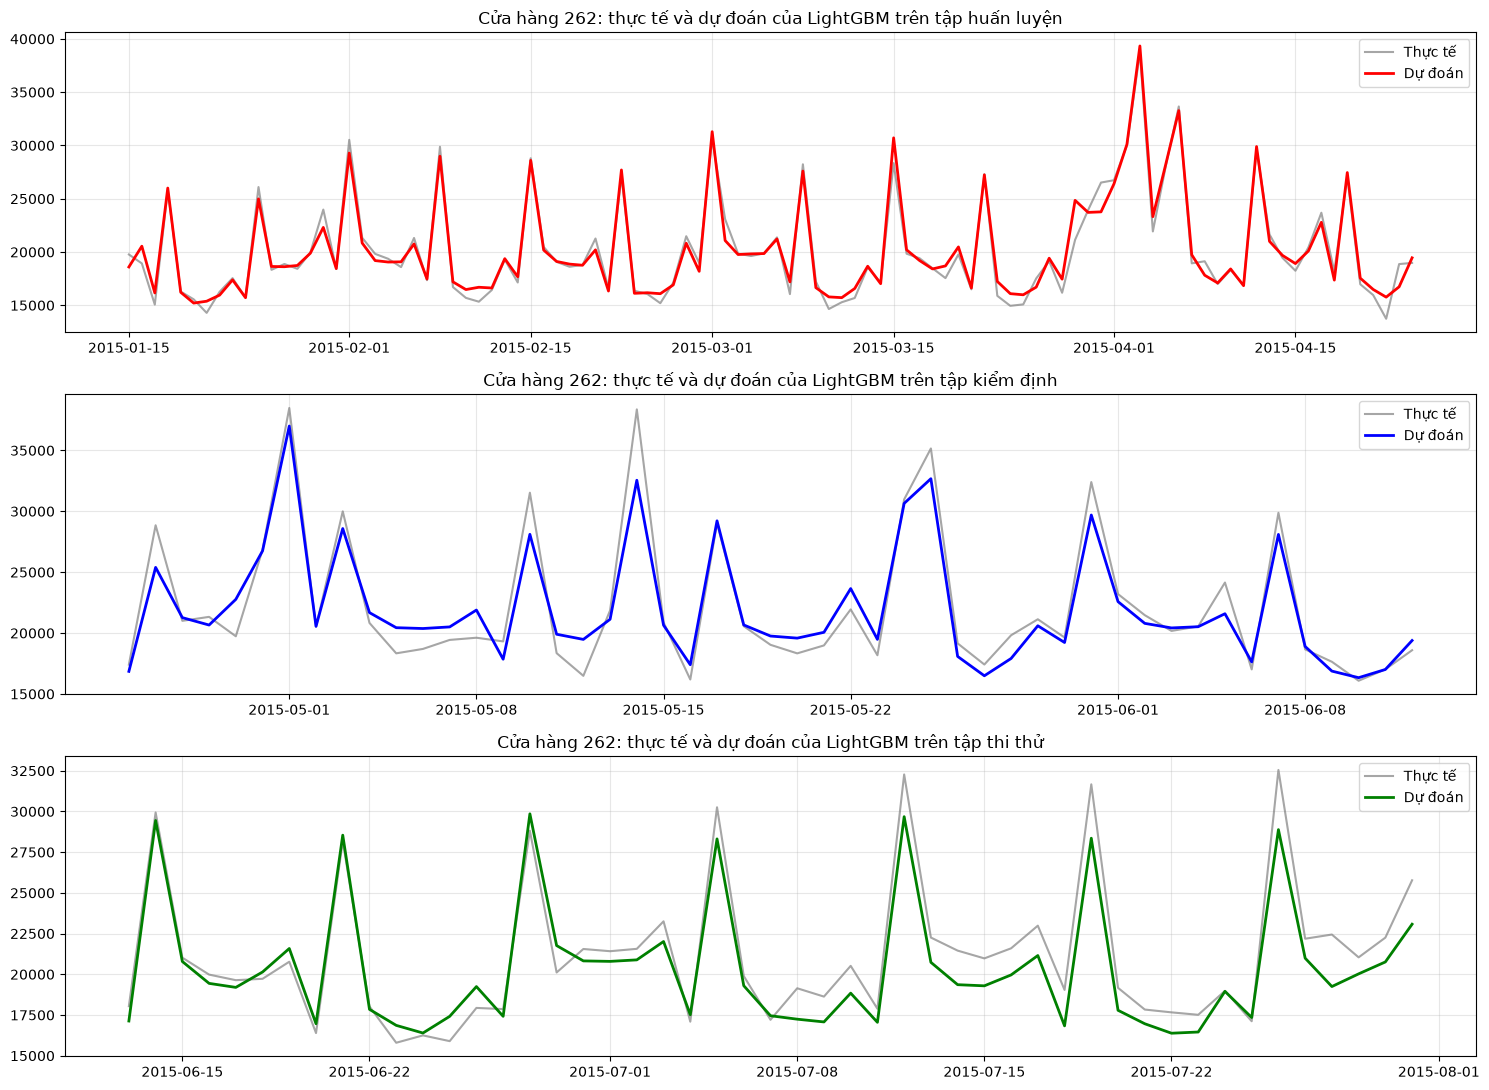

In [ ]:
plot_df_lgb = build_plot_df(model_lgb, sets)
plot_store(plot_df_lgb , 1 , 'LightGBM')
plot_store(plot_df_lgb , 262 , 'LightGBM')

Độ quan trọng đặc trưng (theo gain) để giải thích mô hình LightGBM.

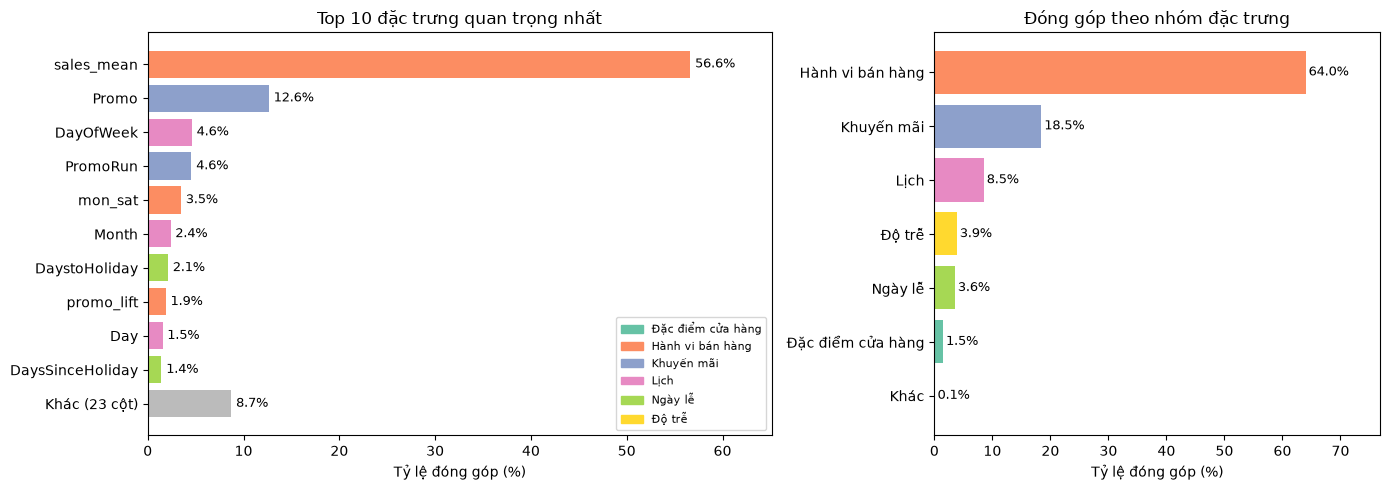

In [ ]:
plot_importance_grouped(get_importance(model_lgb), 'LightGBM')

**4.4 Huấn luyện mô hình Rigde Regression**

Chuẩn bị dữ liệu để huấn luyện mô hình.

In [81]:
d = my_data

# Số tuần đã tham gia Promo2 (0 nếu không tham gia hoặc chưa bắt đầu)
since_year = d['Store'].map(data_root['Promo2SinceYear']).fillna(0)
iso = d['Date'].dt.isocalendar()
weeks_now   = iso['year'].astype(int) * 52 + iso['week'].astype(int)
weeks_start = since_year * 52 + d['Promo2SinceWeek']
d['Promo2_weeks'] = np.where(d['Promo2'] == 1, (weeks_now - weeks_start).clip(lower=0), 0)

# Chia khoảng cho các quan hệ cong
d['Day_bin']      = pd.cut(d['Day'], [0, 5, 15, 25, 31], labels=['dau', 'giua1', 'giua2', 'cuoi']).astype(str)
hol_bins          = [-1, 0, 1, 2, 7, 14, 1000]
hol_labels        = ['0', '1', '2', '3-7', '8-14', '15+']
d['HolTo_bin']    = pd.cut(d['DaystoHoliday'],    hol_bins, labels=hol_labels).astype(str)
d['HolSince_bin'] = pd.cut(d['DaysSinceHoliday'], hol_bins, labels=hol_labels).astype(str)

# Cột tương tác: Ridge không tự học được
d['Promo_DOW']   = d['Promo'].astype(str) + '_' + d['DayOfWeek'].astype(str)
d['Promo_Type']  = d['Promo'].astype(str) + '_' + d['StoreType'].astype(str)

In [82]:
X_train_ridge = d[d['Date'] <= TRAIN_END].drop(columns=['Sales' , 'Date'])
X_valid_ridge = d[(d['Date'] > TRAIN_END) & (d['Date'] <= VALID_END)].drop(columns=['Sales' , 'Date'])
X_test_ridge = d[d['Date'] > VALID_END].drop(columns=['Sales' , 'Date'])

Tạo pipeline cho mô hình.

In [83]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge

ridge_cols = {
    'onehot':    ['StoreType', 'Assortment', 'Cluster_comp', 'Cluster_behavior', 'PromoRun',
                  'DayOfWeek', 'Month', 'Day_bin', 'HolTo_bin', 'HolSince_bin',
                  'Promo_DOW', 'Promo_Type'],
    'log_scale': ['CompetitionDistance', 'CompetitorLongevity', 'lag_49', 'lag_56', 'lag_63'],
    'scale':     ['sales_mean', 'sales_cv', 'promo_lift', 'mon_sat', 'dec_lift', 'basket',
                  'LastPromo', 'Promo2_weeks'],
    'binary':    ['Promo', 'PromoPrev', 'PromoNext', 'Promo2', 'Promo2_Active']
}
# Cột bỏ hẳn: Store, Year, Promo2SinceWeek, Promo2SinceYear, Day, DaystoHoliday, DaysSinceHoliday

prep_ridge = ColumnTransformer([
    ('oh',  OneHotEncoder(handle_unknown='ignore', min_frequency=50), ridge_cols['onehot']),
    ('log', make_pipeline(FunctionTransformer(np.log1p , feature_names_out='one-to-one'), StandardScaler()), ridge_cols['log_scale']),
    ('num', StandardScaler(), ridge_cols['scale']),
    ('bin', 'passthrough', ridge_cols['binary']),
])


Chuẩn hoá dữ liệu trước huấn luyện.

In [84]:
lag_cols = ['lag_49', 'lag_56', 'lag_63']

def clean_for_ridge(X):
    X = X.copy()
    # 1. Không cho số âm vào log
    X[ridge_cols['log_scale']] = X[ridge_cols['log_scale']].clip(lower=0)
    # 2. Vô cực từ các phép chia → coi như "không chênh lệch" (tỷ lệ = 1)
    ratio_cols = ['promo_lift', 'mon_sat', 'dec_lift', 'basket', 'sales_cv']
    X[ratio_cols] = X[ratio_cols].replace([np.inf, -np.inf], np.nan).fillna(1)
    return X

X_train_ridge = clean_for_ridge(X_train_ridge)
X_valid_ridge = clean_for_ridge(X_valid_ridge)

# 3. Lag vẫn còn NaN → bỏ dòng thiếu, ở cả X và y
keep_tr = X_train_ridge[lag_cols].notna().all(axis=1)
keep_va = X_valid_ridge[lag_cols].notna().all(axis=1)
X_train_ridge, y_train_ridge = X_train_ridge[keep_tr], y_train_log[keep_tr]
X_valid_ridge, y_valid_ridge = X_valid_ridge[keep_va], y_valid_log[keep_va]

Huấn luyện mô hình.

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['StoreType','Assortment','Cluster_comp',...,'PromoNext','Promo2', 'Promo2_Active']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('oh', ...), ('log', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. T

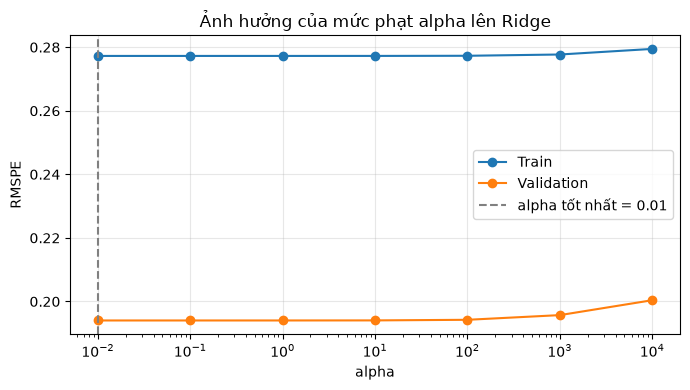

In [85]:
def rmspe(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = y_true != 0                      # tránh chia cho 0
    pct = (y_true[mask] - y_pred[mask]) / y_true[mask]
    return np.sqrt(np.mean(pct ** 2))
alphas = [0.01, 0.1, 1, 10, 100, 1000, 10000]
rows = []
for a in alphas:
    ridge.set_params(ridge__alpha=a).fit(X_train_ridge[all_cols], y_train_ridge)
    for name, X, y in [('Train', X_train_ridge, y_train_ridge), ('Validation', X_valid_ridge, y_valid_ridge)]:
        p = np.expm1(ridge.predict(X[all_cols]))
        rows.append(dict(alpha=a, tap=name, RMSPE=rmspe(np.expm1(y), p)))
curve = pd.DataFrame(rows).pivot(index='alpha', columns='tap', values='RMSPE')

ax = curve.plot(marker='o', logx=True, figsize=(7, 4))
best_a = curve['Validation'].idxmin()
ax.axvline(best_a, ls='--', color='gray', label=f'alpha tốt nhất = {best_a}')
ax.set_ylabel('RMSPE'); ax.set_title('Ảnh hưởng của mức phạt alpha lên Ridge')
ax.legend(); ax.grid(alpha=0.3)
save_fig('ridge_alpha_curve')

ridge.set_params(ridge__alpha=best_a).fit(X_train_ridge[all_cols], y_train_ridge)   # fit lại với alpha tốt nhất

93 93


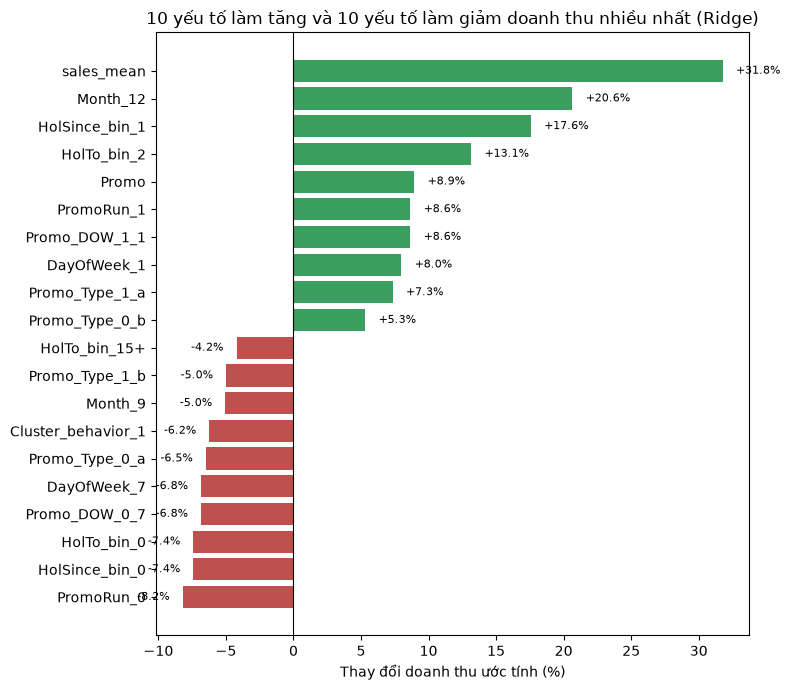

In [92]:
ct = ridge.named_steps['columntransformer']      # ColumnTransformer ĐÃ fit bên trong ridge

# One-hot: hỏi riêng OneHotEncoder (bước này luôn có tên cột)
oh_names = ct.named_transformers_['oh'].get_feature_names_out(ridge_cols['onehot'])

# Các nhóm còn lại giữ nguyên tên, đúng thứ tự khai báo trong ColumnTransformer
names = (list(oh_names) + ridge_cols['log_scale']
         + ridge_cols['scale'] + ridge_cols['binary'])

coef = pd.Series(ridge[-1].coef_, index=names)
print(len(names), len(ridge[-1].coef_))          # hai số phải bằng nhau
top = pd.concat([coef.nlargest(10), coef.nsmallest(10)]).sort_values()
pct = (np.exp(top) - 1) * 100                       # đổi hệ số log → % thay đổi doanh thu

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top.index, pct, color=np.where(pct > 0, '#3a9e5f', '#c0504d'))
ax.axvline(0, color='black', lw=0.8)
for i, v in enumerate(pct):
    ax.text(v + (1 if v > 0 else -1), i, f'{v:+.1f}%', va='center',
            ha='left' if v > 0 else 'right', fontsize=8)
ax.set_xlabel('Thay đổi doanh thu ước tính (%)')
ax.set_title('10 yếu tố làm tăng và 10 yếu tố làm giảm doanh thu nhiều nhất (Ridge)')
plt.tight_layout()
save_fig('ridge_coefficients')

Hệ số của Ridge cho thấy quy mô cửa hàng (sales_mean) là yếu tố ảnh hưởng mạnh nhất, tiếp theo là mùa lễ tháng 12 (+21%). Mô hình phát hiện hành vi mua dồn quanh ngày lễ: doanh thu tăng khoảng 13% hai ngày trước lễ và 18% ngày đầu sau lễ, trong khi chính ngày lễ giảm khoảng 7%. Khuyến mãi làm doanh thu tăng, đặc biệt vào ngày đầu đợt và vào thứ Hai, nhưng kém hiệu quả hơn ở cửa hàng loại b. Các kết quả này nhất quán với phân tích khám phá ở Chương 2

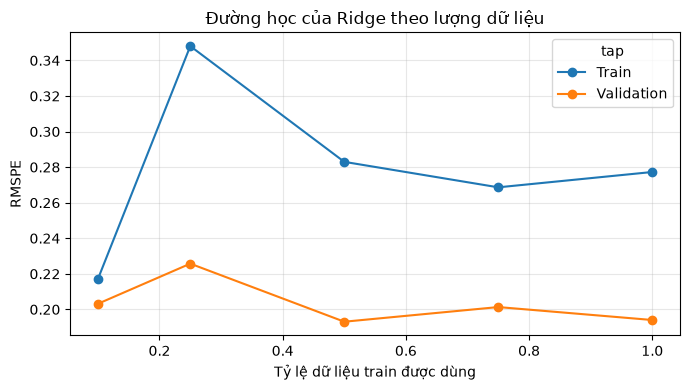

In [ ]:
dates_tr = my_data.loc[X_train_ridge.index, 'Date']
fracs, rows = [0.1, 0.25, 0.5, 0.75, 1.0], []
for f in fracs:
    cut = dates_tr.quantile(1 - f)                 # lấy f% thời gian GẦN NHẤT, giữ đúng thứ tự thời gian
    m = dates_tr >= cut
    ridge.fit(X_train_ridge.loc[m, all_cols], y_train_ridge[m])
    for name, X, y in [('Train', X_train_ridge[m], y_train_ridge[m]), ('Validation', X_valid_ridge, y_valid_ridge)]:
        rows.append(dict(ty_le=f, tap=name, RMSPE=rmspe(np.expm1(y), np.expm1(ridge.predict(X[all_cols])))))
lc = pd.DataFrame(rows).pivot(index='ty_le', columns='tap', values='RMSPE')

ax = lc.plot(marker='o', figsize=(7, 4))
ax.set_xlabel('Tỷ lệ dữ liệu train được dùng'); ax.set_ylabel('RMSPE')
ax.set_title('Đường học của Ridge theo lượng dữ liệu'); ax.grid(alpha=0.3)
save_fig('ridge_learning_curve')

sai số trên tập kiểm định của Ridge gần như không giảm khi tăng lượng dữ liệu huấn luyện (RMSPE khoảng 0,19–0,20 từ 50% dữ liệu trở lên), cho thấy mô hình tuyến tính đã đạt giới hạn khả năng; muốn cải thiện cần mô hình phi tuyến như LightGBM. RMSPE trên tập huấn luyện cao hơn tập kiểm định do giai đoạn 2013–2014 chứa nhiều ngày doanh thu bất thường (gần ngày lễ, giai đoạn thiếu dữ liệu nửa cuối 2014), mà RMSPE phạt rất nặng sai số trên những ngày doanh thu thấp.

**4.5 Huấn luyện mô hình Random Forest**

Chuẩn bị dữ liệu huấn luyện mô hình.

In [93]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from IPython.display import display
import category_encoders as ce
numrical_cols    = X_train.select_dtypes(include='number').columns
categorical_cols = X_train.select_dtypes(include=['object', 'category', 'string']).columns
numrical = Pipeline(steps = [('impute' , SimpleImputer(strategy = 'constant' , fill_value = 0))])
categorical = Pipeline(steps = [('impute' , SimpleImputer(strategy = 'constant' , fill_value = 'missing')) ,
                                ('Target_encoders' , ce.TargetEncoder(smoothing = 10.0))])
preprocessing = ColumnTransformer( transformers = [('num' , numrical , numrical_cols) ,
                                                 ('cate' , categorical , categorical_cols)] ,
                                                  verbose_feature_names_out=False)
preprocessing.set_output(transform='pandas')
display(preprocessing)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cate', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. Th

Huấn luyện mô hình.

In [130]:
from sklearn.ensemble import RandomForestRegressor
model_RandomForest = RandomForestRegressor( n_estimators = 100 , random_state = 0 , n_jobs=-1, max_depth=20 , verbose = False)
model_pipeline = Pipeline ( steps = [('preprocessing' , preprocessing) ,
                                     ('model' , model_RandomForest)])
model_pipeline = model_pipeline.fit(X_train , y_train_log)
display(model_pipeline)

MemoryError: could not allocate 4194304 bytes

C:\Users\Admin\AppData\Local\Temp\ipykernel_4828\3114382797.py:14: RuntimeWarning: overflow encountered in expm1
  return [rmspe(true, np.expm1(p)) for p in cum_mean]
C:\Users\Admin\AppData\Local\Temp\ipykernel_4828\1580680572.py:6: RuntimeWarning: overflow encountered in square
  return np.sqrt(np.mean(pct ** 2))
C:\Users\Admin\AppData\Local\Temp\ipykernel_4828\3114382797.py:14: RuntimeWarning: overflow encountered in expm1
  return [rmspe(true, np.expm1(p)) for p in cum_mean]


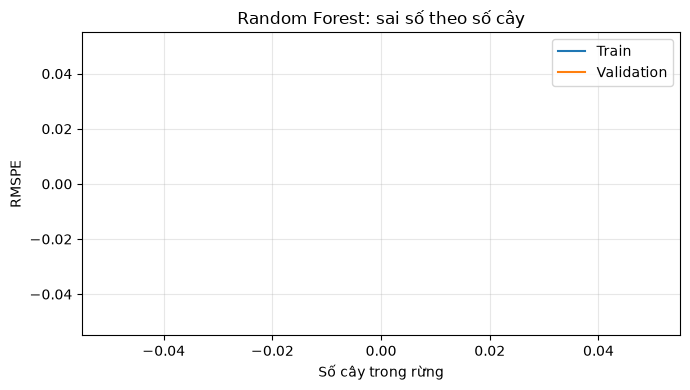

In [ ]:
# Lấy mẫu để chạy nhanh (dự đoán từng cây trên toàn bộ dữ liệu khá lâu)
pre = model_pipeline.named_steps['preprocessing']
rf  = model_pipeline.named_steps['model']

idx_tr = X_train.sample(20_000, random_state=0).index
idx_va = X_valid.sample(20_000, random_state=0).index
X_tr_pre = pre.transform(X_train.loc[idx_tr])
X_va_pre = pre.transform(X_valid.loc[idx_va])

def staged_rmspe(model, X, y_log):
    preds = np.stack([t.predict(X.values) for t in model.estimators_])        # dự đoán của từng cây
    cum_mean = np.cumsum(preds, axis=0) / np.arange(1, len(preds) + 1)[:, None]   # trung bình k cây đầu
    true = np.expm1(np.asarray(y_log))
    return [rmspe(true, np.expm1(p)) for p in cum_mean]

curve_tr = staged_rmspe(model_RandomForest, X_tr_pre.loc[idx_tr], y_train_log.loc[idx_tr])
curve_va = staged_rmspe(model_RandomForest, X_va_pre.loc[idx_va], y_valid_log.loc[idx_va])

n = np.arange(1, len(curve_va) + 1)
plt.figure(figsize=(7, 4))
plt.plot(n, curve_tr, label='Train')
plt.plot(n, curve_va, label='Validation')
plt.xlabel('Số cây trong rừng'); plt.ylabel('RMSPE')
plt.title('Random Forest: sai số theo số cây')
plt.legend(); plt.grid(alpha=0.3)
save_fig('rf_error_vs_trees')

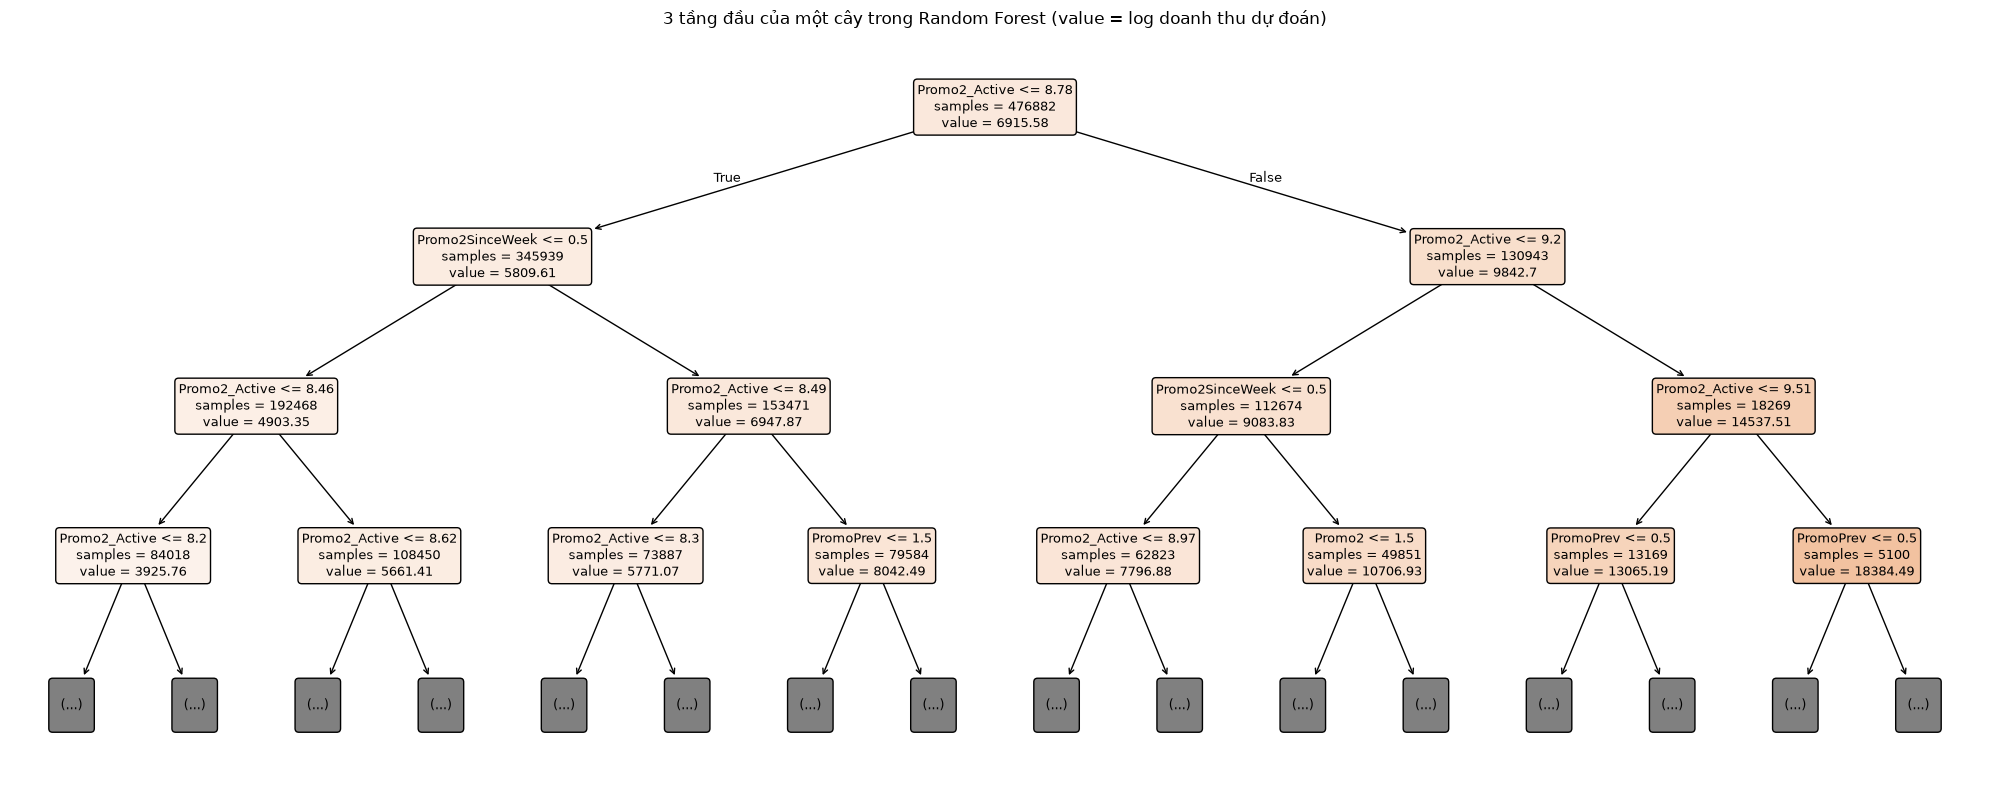

In [112]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 8))
plot_tree(model_RandomForest.estimators_[0], max_depth=3,       # chỉ vẽ 3 tầng đầu cho dễ đọc
          feature_names=X_train.columns, filled=True, rounded=True,
          impurity=False, fontsize=9, precision=2)
plt.title('3 tầng đầu của một cây trong Random Forest (value = log doanh thu dự đoán)')
save_fig('rf_one_tree')

**4.6 Huấn luyện mô hình XGBoost**

Tạo mô hình XGBoost và huấn luyện.

In [100]:
from xgboost import XGBRegressor as xgb
import time

t0 = time.time()
model_xgb = xgb(
    n_estimators=3000, learning_rate=0.1, max_depth=8,
    subsample=0.8, colsample_bytree=0.8,
    tree_method='hist', enable_categorical=True,     
    early_stopping_rounds=50,                     
    eval_metric='rmse', importance_type='gain',
    n_jobs=-1, random_state=0, verbosity=0,
)
model_xgb.fit(X_train, y_train_log,
              eval_set=[(X_valid, y_valid_log)],
              verbose=200)                           
print(f'Số cây tối ưu: {model_xgb.best_iteration} | {time.time() - t0:.0f} giây')

[0]	validation_0-rmse:0.37746
[200]	validation_0-rmse:0.11502
[400]	validation_0-rmse:0.11215
[600]	validation_0-rmse:0.11095
[800]	validation_0-rmse:0.11029
[1000]	validation_0-rmse:0.10973
[1200]	validation_0-rmse:0.10939
[1400]	validation_0-rmse:0.10917
[1564]	validation_0-rmse:0.10901
Số cây tối ưu: 1514 | 370 giây


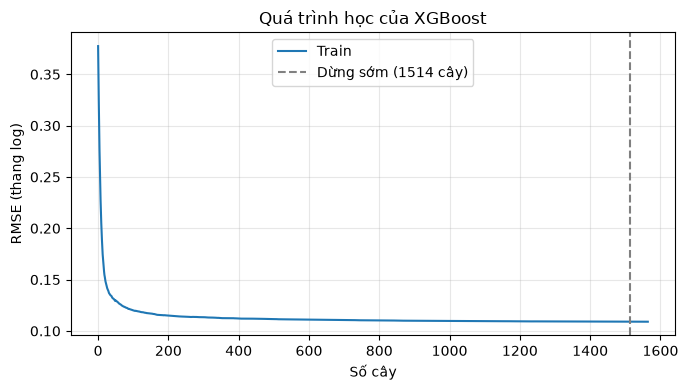

In [105]:
plot_learning_curve(model_xgb, 'XGBoost')

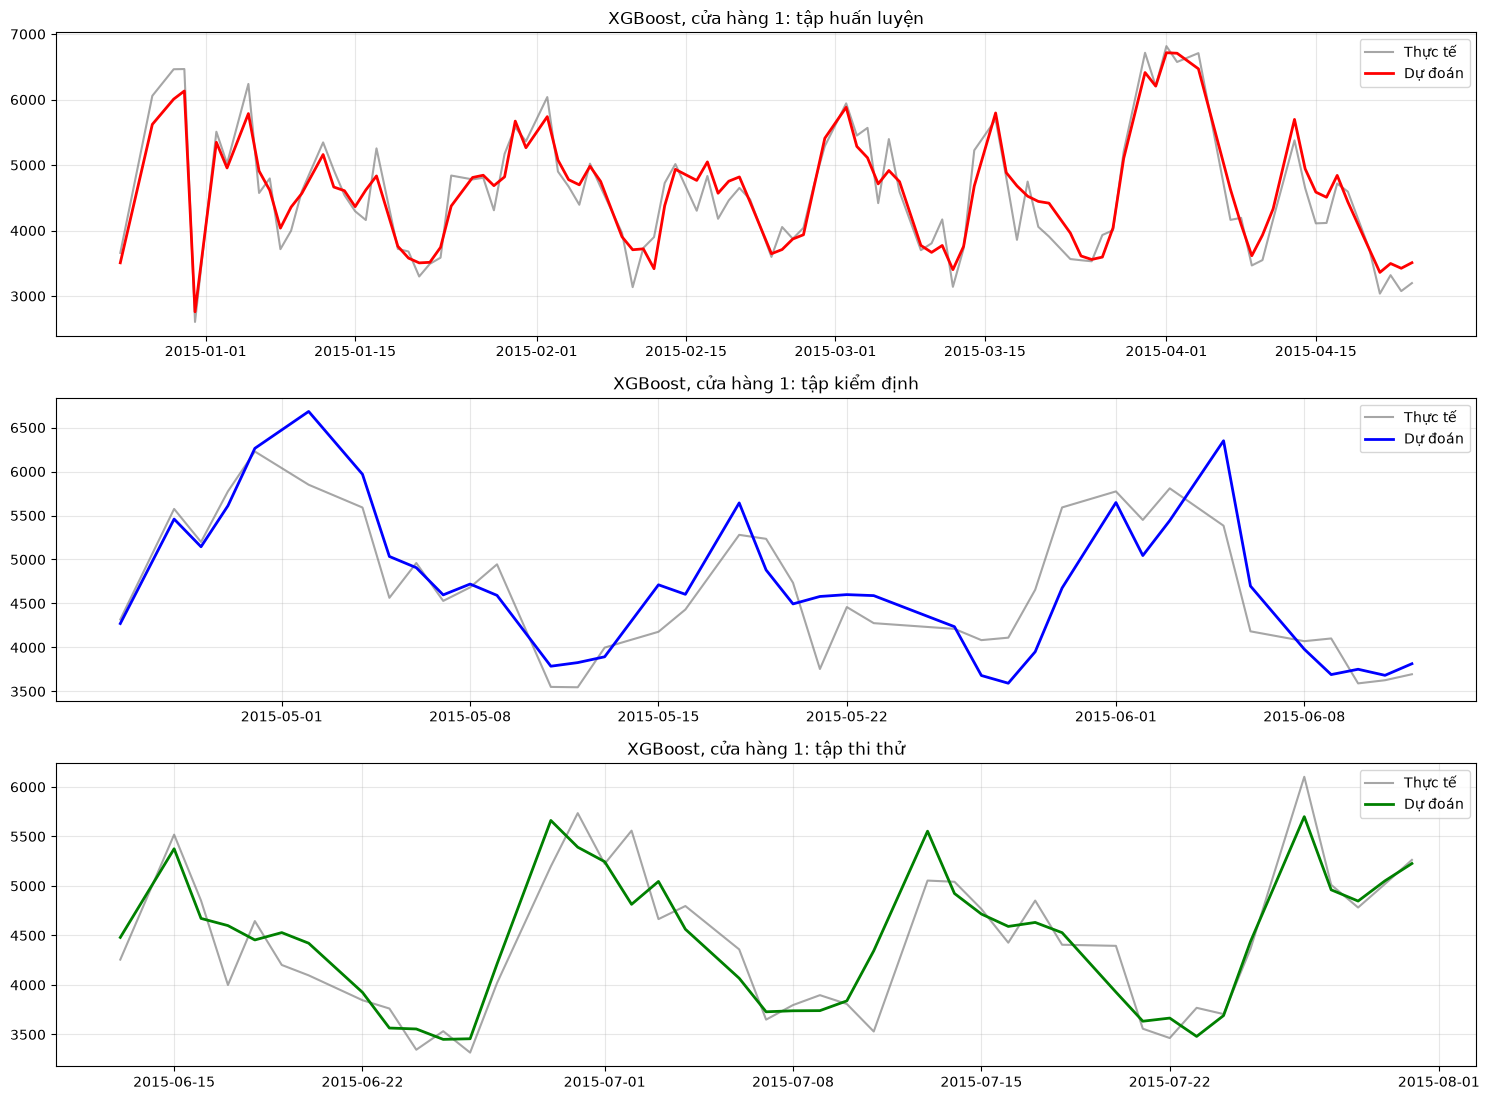

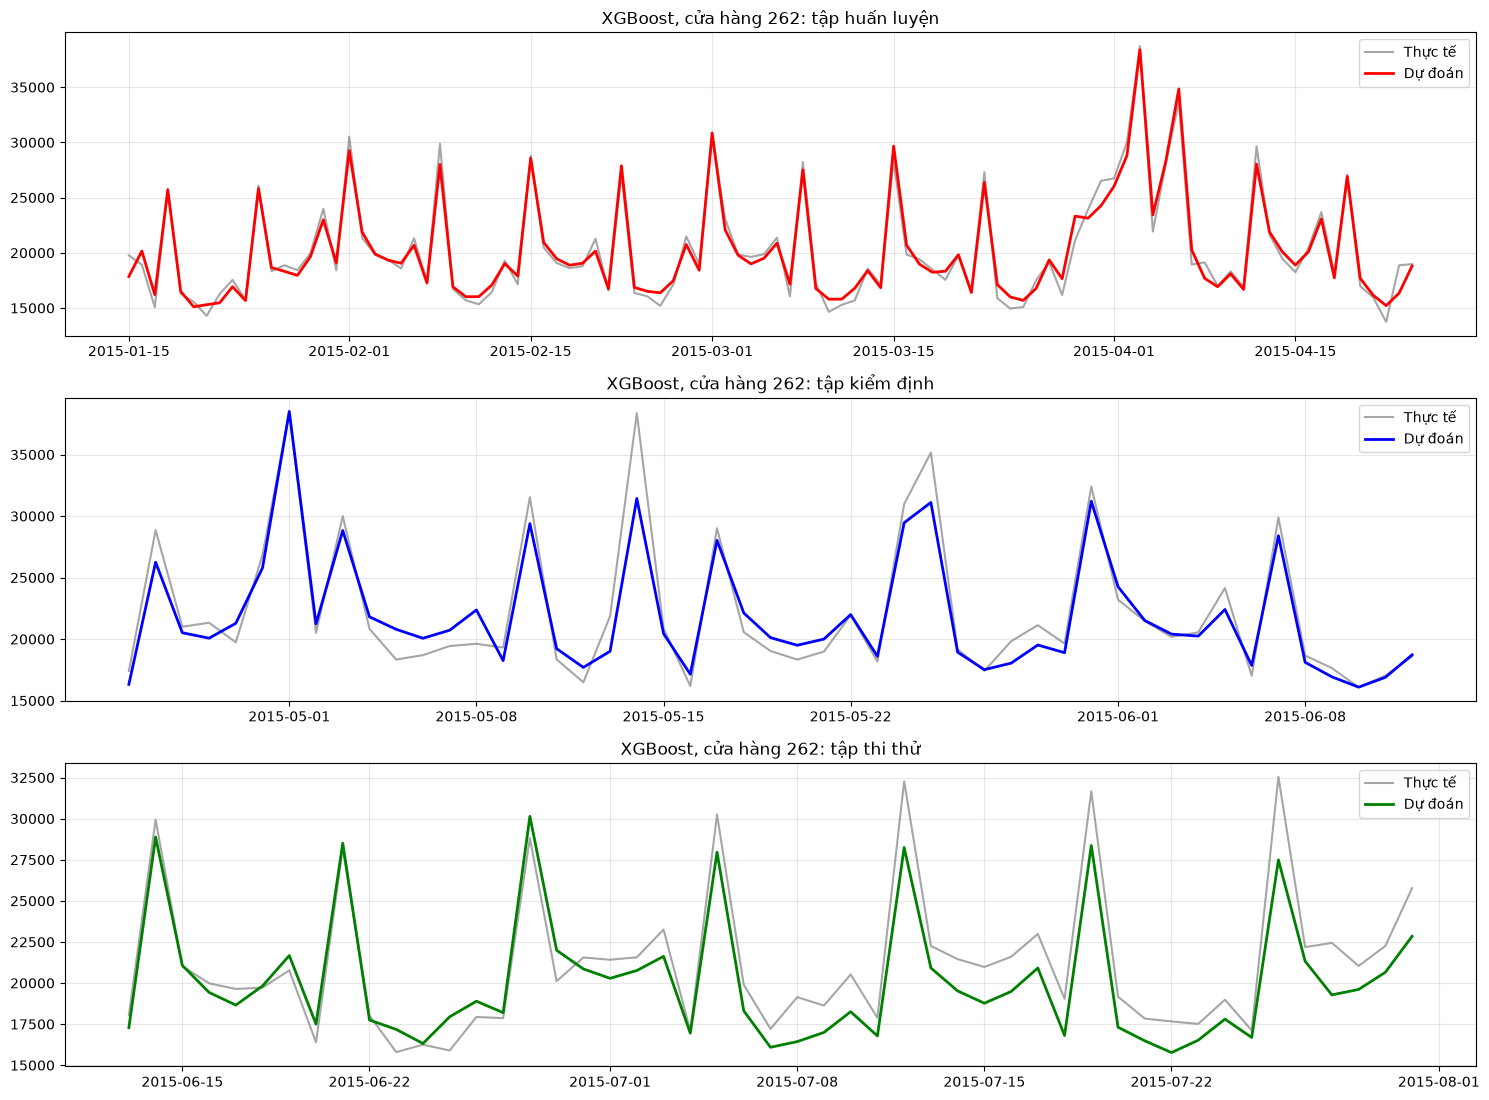

In [106]:
plot_df_xgb = build_plot_df(model_xgb, sets)
plot_store(plot_df_xgb, 1,   'XGBoost')
plot_store(plot_df_xgb, 262, 'XGBoost')

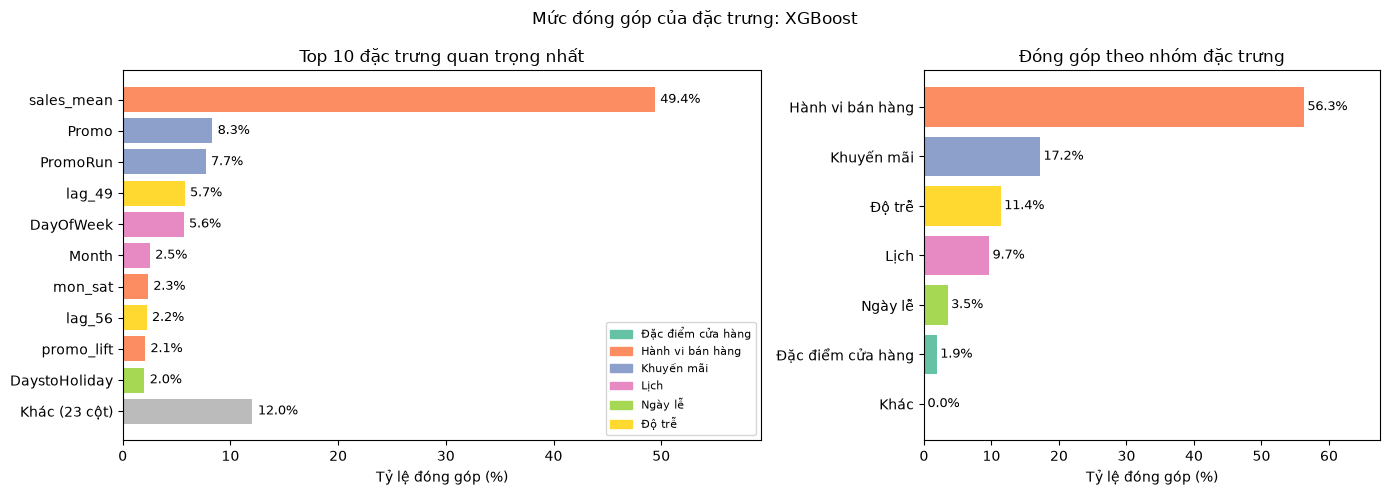

In [107]:
plot_importance_grouped(get_importance(model_xgb), 'XGBoost')